# Edge elements: pre- and post-processing of a 3D coil sector

This notebook takes the example `examples/coil_3D_avoltemf_edge` through a complete workflow around its macro:

1. **pre-processing**: look at the mesh, the regions, the model data and the edge DOFs before running anything;
2. **run** the example macro as it is, together with its nodal counterpart `examples/coil_3D_avoltemf`;
3. **post-processing**: read the outputs, compute the coil circuit quantities, the eddy current of the passive ring
   and the field, and compare the two formulations of the vector potential.

The model is the coil and passive ring of the 2D examples, revolved about the y axis and modelled on a 30 degree
cyclic sector. The lower ring is a 2000-turn stranded coil fed through its terminals (VOLT, EMF): first by a current
of 100 A, then by a voltage of 10 kV. The upper ring is a passive massive conductor (A and V).

With `AV3D_edge` the vector potential is discretized with **edge** (Nedelec) elements: its DOFs are the circulations
of A along the mesh edges, stored on the midside nodes of a quadratic mesh, while V, VOLT and EMF stay nodal. There is
no Coulomb gauge term: a tree-cotree decomposition of the edges fixes the gauge. The nodal model `AV3D_nodal` solves
the same problem with a nodal A and a penalty gauge. Theory: *Element library* (AV3D_edge, AV3D_nodal); user manual:
*Boundary conditions* (gauging edge elements, cyclic symmetry).

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("../../examples/coil_3D_avoltemf_edge").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_coil_3D_avoltemf_edge_"))
for name in ("coil_3D_avoltemf_edge.vtu", "model_data.json", "macro.py"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

import json, subprocess, sys, time
from pytec3d import element_library

working in a temporary folder: pytec3d_coil_3D_avoltemf_edge_62oh0lqs


## 1. Pre-processing: the mesh and the regions

The mesh is read without loading it into a solver: `meshes.read_mesh` gives the VTK grid with its arrays (TYPE,
MATERIAL, CONSTANT, the components of the model). The edge DOFs need a quadratic mesh (HEX20 / WEDGE15): their values
live on the midside nodes, flagged by the point array `MidsideNodes`.

In [2]:
grid = pv.wrap(meshes.read_mesh("coil_3D_avoltemf_edge.vtu"))
print(f"{grid.n_points} points, {grid.n_cells} cells:", dict(zip(*np.unique(grid.celltypes, return_counts=True))),
      "(25 = HEX20, 26 = WEDGE15)")
print("midside nodes:", int(np.sum(grid.point_data["MidsideNodes"])) if "MidsideNodes" in grid.point_data else "-")
data = json.load(open("model_data.json"))
families = dict(enumerate(element_library.element_types())) if hasattr(element_library, "element_types") else {}
domains = dict(enumerate(element_library.domains()))
for tid, row in sorted(data["element_types"].items(), key=lambda kv: int(kv[0])):
    n = int(np.sum(grid.cell_data["TYPE"] == int(tid)))
    print(f"TYPE {tid}: element_type {row['element_type']} {families.get(row['element_type'], '')}, "
          f"{domains[row['option1']]:26s} {n:6d} cells")
for mid, mat in sorted(data["materials"].items(), key=lambda kv: int(kv[0])):
    print(f"MATERIAL {mid}: mur = {mat['mur'][0][0]:g}, rho = {mat['rho'][0][0]:g} Ohm m")
coil = data["constants"]["1"]
print("coil real constants:", {k: coil[k] for k in coil if k in ("cross_section", "turns", "resistance", "volume", "symmetry", "T")})

18821 points, 4000 cells: {np.uint8(25): np.int64(3800), np.uint8(26): np.int64(200)} (25 = HEX20, 26 = WEDGE15)
midside nodes: 13860
TYPE 21: element_type 2 AV3D_edge, NON_CONDUCTING               3840 cells
TYPE 23: element_type 2 AV3D_edge, STRANDED_COIL                  80 cells
TYPE 24: element_type 2 AV3D_edge, SOLID_CONDUCTOR                80 cells
MATERIAL 21: mur = 1, rho = 1 Ohm m
MATERIAL 23: mur = 1, rho = 3e-07 Ohm m
MATERIAL 24: mur = 1, rho = 2e-08 Ohm m
coil real constants: {'cross_section': 0.04, 'turns': 2000.0, 'volume': 0.12566370614359, 'resistance': 20.0, 'symmetry': 12.0, 'T': [0.0, 1.0, 0.0]}


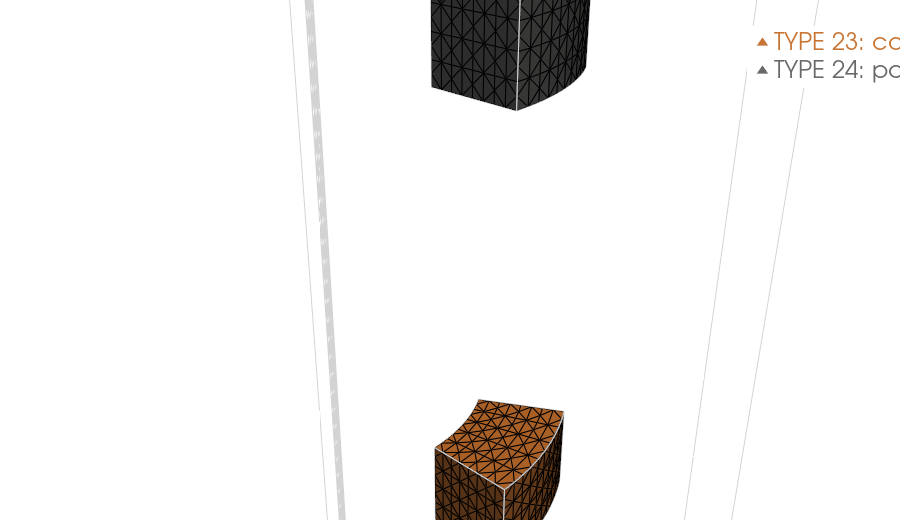

In [3]:
types = grid.cell_data["TYPE"]
pl = pv.Plotter(window_size=(900, 520))
air = grid.threshold(value=(float(types.min()), float(types.min())), scalars="TYPE")
pl.add_mesh(air.extract_feature_edges(), color="lightgray")
for tid, color, label in ((int(t), c, l) for t, c, l in zip(sorted(set(types.tolist()))[1:], ("#c87533", "dimgray", "#5a8fbf"),
                                                          ("coil", "passive ring", "other"))):
    part = grid.threshold(value=(tid, tid), scalars="TYPE")
    if part.n_cells:
        pl.add_mesh(part, color=color, show_edges=True, edge_color="black", line_width=0.3, label=f"TYPE {tid}: {label}")
pl.add_legend(bcolor="white", size=(0.3, 0.12))
pl.camera_position = [(1.6, 0.9, 1.2), (0.35, 0.0, -0.1), (0, 1, 0)]
pl.show()

The 30 degree sector: the coil (lower ring) and the passive ring (upper ring) in the air box. The macro sets the
boundary conditions on this grid: cyclic symmetry between the faces at 0 and 30 degrees (edge values are scalars: no
frame rotation), tangential A = 0 on the outer boundary (component 2 of `_A` on the midside nodes), and the
tree-cotree gauge (`tree_gauge.tree_gauge`), which writes A = 0 on the tree edges into `_A`.

## 2. Run the examples

The macros are run as they are, each in its own copy of the example folder. `coil_3D_avoltemf` is the same model with
nodal elements (HEX8 / WEDGE6, nodal frames rotated on the second cyclic face).

In [4]:
NODAL = WORK / "coil_3D_avoltemf"
NODAL.mkdir()
for name in ("coil_3D_avoltemf.vtu", "model_data.json", "macro.py"):
    shutil.copy(CASE.parent / "coil_3D_avoltemf" / name, NODAL / name)
for folder in (WORK, NODAL):
    started = time.perf_counter()
    run = subprocess.run([sys.executable, "macro.py"], cwd=folder, capture_output=True, text=True)
    assert run.returncode == 0, run.stderr[-3000:]
    print(f"{folder.name:24s} solved in {time.perf_counter() - started:5.1f} s:",
          sorted(p.name for p in (folder / "output").glob("*_out_*.vtu")))

pytec3d_coil_3D_avoltemf_edge_62oh0lqs solved in   4.8 s: ['coil_3D_avoltemf_edge_out_1.vtu', 'coil_3D_avoltemf_edge_out_2.vtu']
coil_3D_avoltemf         solved in   3.8 s: ['coil_3D_avoltemf_out_1.vtu', 'coil_3D_avoltemf_out_2.vtu']


## 3. Post-processing

Each step wrote `output/<case>_out_<n>.vtu` (the solved model: point arrays A, V, VOLT, EMF, CURR, cell arrays B,
Jt, Js) and a line of `<case>_steps.csv`. We read both runs and compare:

* the **circuit** of the coil: VOLT and EMF on its nodes (all the coil nodes share one value through the coupling
  `CP_0 = 1`) and the coil current from the circuit equation, $I = (\mathrm{VOLT} - \mathrm{EMF}) / R$ (the
  array `CURR` holds the imposed current, a load: 0 on the voltage-driven step);
* the toroidal **eddy current** of the passive ring, $I = \sum J_\varphi\,a$ over a meridian cut, with the cell area
  $a = V_{cell} / (r\,\Delta\theta)$ (the sector has one cell in theta per element layer, 30 degrees);
* the **field** $|B|$ on the meridian plane in the middle of the sector.

In [5]:
def results(folder, case, step):
    g = pv.wrap(meshes.read_mesh(str(folder / "output" / f"{case}_out_{step}.vtu"), reset_arrays=False))
    out = {"grid": g}
    coil_nodes = g.point_data["CP_0"] == 1
    for name in ("VOLT", "EMF"):
        values = g.point_data[name][coil_nodes]
        out[name] = float(values[np.argmax(np.abs(values))]) if values.size else 0.0
    out["I_coil"] = (out["VOLT"] - out["EMF"]) / data["constants"]["1"]["resistance"]
    c = g.cell_data["cell_centroids"]
    r = np.hypot(c[:, 0], c[:, 2])
    theta = np.arctan2(-c[:, 2], c[:, 0])
    j_phi = (g.cell_data["Jt"][:, 0] * c[:, 2] - g.cell_data["Jt"][:, 2] * c[:, 0]) / r   # e_phi = (z, 0, -x) / r
    passive = g.cell_data["TYPE"] == np.unique(g.cell_data["TYPE"])[2]
    out["I_passive"] = float(np.sum(j_phi[passive] * np.abs(g.cell_data["cell_volume"][passive]) / (r[passive] * np.radians(30.0))))
    return out

rows = []
for step in (1, 2):
    for label, folder, case in (("edge", WORK, "coil_3D_avoltemf_edge"), ("nodal", NODAL, "coil_3D_avoltemf")):
        res = results(folder, case, step)
        rows.append((step, label, res))
        print(f"step {step} {label:6s} VOLT = {res['VOLT']:10.2f} V   EMF = {res['EMF']:10.2f} V   "
              f"I_coil = {res['I_coil']:8.3f} A   I_passive = {res['I_passive']:9.2f} A")

step 1 edge   VOLT = 39742281.05 V   EMF = 39740281.05 V   I_coil =  100.000 A   I_passive =  -5248.76 A
step 1 nodal  VOLT = 39834115.21 V   EMF = 39832111.55 V   I_coil =  100.183 A   I_passive =  -5270.80 A
step 2 edge   VOLT =   10000.00 V   EMF =    7999.60 V   I_coil =  100.020 A   I_passive =  -5249.19 A
step 2 nodal  VOLT =   10000.00 V   EMF =    7995.94 V   I_coil =  100.203 A   I_passive =  -5271.24 A


Step 1 imposes the coil current (100 A): VOLT and EMF follow from the circuit equation, VOLT = R I + EMF. Their
values are about 40 MV (the current rises in 10 microseconds), so their 2 kV difference carries the rounding of the
stored values: the nodal run shows 100.18 A instead of 100 A. Step 2 imposes the terminal voltage (10 kV): the
current follows. The passive ring carries the eddy current induced by the
change of the coil flux, opposite to the coil current. Both formulations give the same circuit quantities and the same
ring current, to the discretization error: the edge model has more A DOFs on a mesh of the same cells.

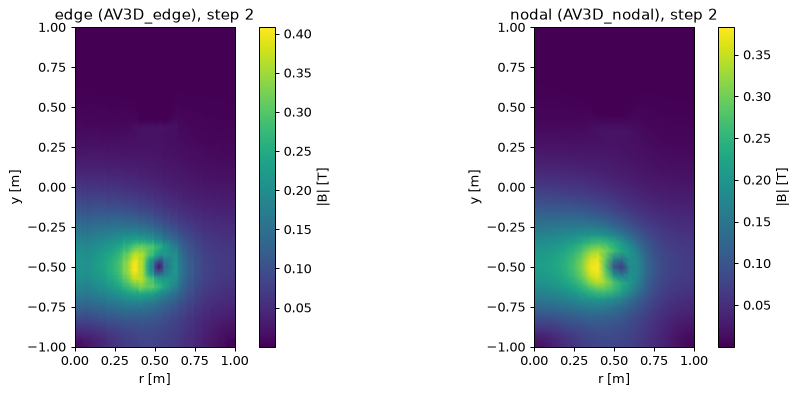

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (label, folder, case) in zip(axes, (("edge (AV3D_edge)", WORK, "coil_3D_avoltemf_edge"),
                                              ("nodal (AV3D_nodal)", NODAL, "coil_3D_avoltemf"))):
    g = pv.wrap(meshes.read_mesh(str(folder / "output" / f"{case}_out_2.vtu"), reset_arrays=False))
    a = np.radians(15.0)
    cut = g.slice(normal=(-np.sin(a), 0.0, -np.cos(a)), origin=(0.0, 0.0, 0.0))
    pts = cut.points
    r, y = np.hypot(pts[:, 0], pts[:, 2]), pts[:, 1]
    cut = cut.cell_data_to_point_data()
    b = np.linalg.norm(cut.point_data["B"], axis=1)
    tri = cut.triangulate()
    faces = tri.faces.reshape(-1, 4)[:, 1:]
    m = ax.tripcolor(r, y, faces, b, shading="gouraud", cmap="viridis")
    fig.colorbar(m, ax=ax, label="|B| [T]")
    ax.set_aspect("equal"); ax.set_xlim(0, 1.0); ax.set_ylim(-1.0, 1.0)
    ax.set_xlabel("r [m]"); ax.set_ylabel("y [m]"); ax.set_title(f"{label}, step 2")
fig.tight_layout()

The field of the voltage-driven coil on the meridian plane at 15 degrees, for both formulations: the same pattern,
concentrated around the coil and coupled to the passive ring. Edge elements represent the tangential continuity of A
exactly and need no gauge penalty; nodal elements are cheaper per cell. To go further: change the voltage or the time
step in the macro and compare again; add iron (`examples/coil_3D_avoltemf_edge_ferr`).